# Maintenance scheduling

A city's road department has a backlog of repair jobs and three crews to do them. Each job takes a
number of working days, cannot start before it is ready, and has an ideal end date and a final
deadline. Jobs in the same district should not run at once, because they would close neighbouring
streets, and only one crane is available. The question is **which crew does each job, and when**.

In this notebook you will:

1. describe a backlog of jobs as Python objects,
2. solve it and draw the crew calendar against ready dates and deadlines,
3. check the result yourself, without trusting the solver's score,
4. change the rules, and see what a different objective costs,
5. add and remove crews to see what capacity buys,
6. restart from an existing plan, and fit in an urgent job with pinned work.

Requires Python 3.11+: `pip install optimaru matplotlib`

In [1]:
from datetime import date, timedelta

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator

from optimaru import maintenance_scheduling as mnt
from optimaru.maintenance_scheduling import constraints as rules
from optimaru.maintenance_scheduling.models import CrewModel, JobModel, MaintenanceScheduleModel

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED = "#52514e", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "legend.frameon": False, "font.size": 10,
})

## 1. Describe the backlog

Three objects make up a schedule. Dates are `datetime.date` values, and every end date is exclusive
(`to_date`, `max_end_date`, `ideal_end_date` and the result's `end_date`):
a job with `max_end_date` on a Friday must finish by the end of Thursday.

| Object | What it holds |
| --- | --- |
| `CrewModel` | one crew, which can do at most one job per day |
| `JobModel` | one job: working days, ready date, ideal end, deadline, tags |
| `MaintenanceScheduleModel` | the calendar `[from_date, to_date)`, the crews and the jobs |

The solver fills in `crew_id` and `start_date` on every job.

Crews work Monday to Friday. A job may only start on a weekday inside the calendar, and its
`end_date` skips weekends. Tags are free text: here each job carries its district, and some carry
`Crane`.

The department below is fictional. The work is close to what three crews can do in eight weeks.

In [2]:
FIRST_DAY, WEEKS = date(2030, 3, 4), 8
DISTRICTS = ["Harbour", "Old town", "Ring road", "Riverside"]
WORKS = ["resurfacing", "drainage", "lighting", "signals", "barriers", "culvert", "kerbs", "joints"]


def make_jobs(count=23):
    rng = np.random.default_rng(3)
    jobs = []
    for i in range(count):
        days = int(rng.integers(2, 9))
        ready = FIRST_DAY + timedelta(days=int(rng.integers(0, 7 * WEEKS - 14)))
        while ready.weekday() > 4:
            ready += timedelta(days=1)
        ideal_end = ready + timedelta(days=int(days * 1.4) + int(rng.integers(3, 15)))
        deadline = ideal_end + timedelta(days=int(rng.integers(3, 15)))
        tags = [DISTRICTS[int(rng.integers(0, len(DISTRICTS)))]]
        if rng.random() < 0.35:
            tags.append("Crane")
        jobs.append(JobModel(
            id=f"J{i + 1:02d}", name=f"{tags[0]} {WORKS[i % len(WORKS)]}", duration_in_days=days,
            min_start_date=ready, ideal_end_date=ideal_end, max_end_date=deadline, tags=tags,
        ))
    return jobs


def make_schedule(crew_count=3):
    """A fresh, unsolved schedule."""
    crews = [CrewModel(id=f"C{k + 1}", name=f"Crew {k + 1}") for k in range(crew_count)]
    return MaintenanceScheduleModel(from_date=FIRST_DAY, to_date=FIRST_DAY + timedelta(weeks=WEEKS),
                                    crews=crews, jobs=make_jobs())


problem = make_schedule()
work_days = sum(j.duration_in_days for j in problem.jobs)
print(f"{len(problem.jobs)} jobs, {len(problem.crews)} crews")
print(f"{work_days} days of work, {len(problem.crews) * 5 * WEEKS} crew days in the calendar")
print("crane jobs:", sum("Crane" in j.tags for j in problem.jobs))

23 jobs, 3 crews
105 days of work, 120 crew days in the calendar
crane jobs: 7


Each row below is one job. The bar runs from its ready date to its deadline, the tick marks its ideal
end, and gray bands are weekends. How much room a job has is the gap between that bar and its length,
printed on the right.

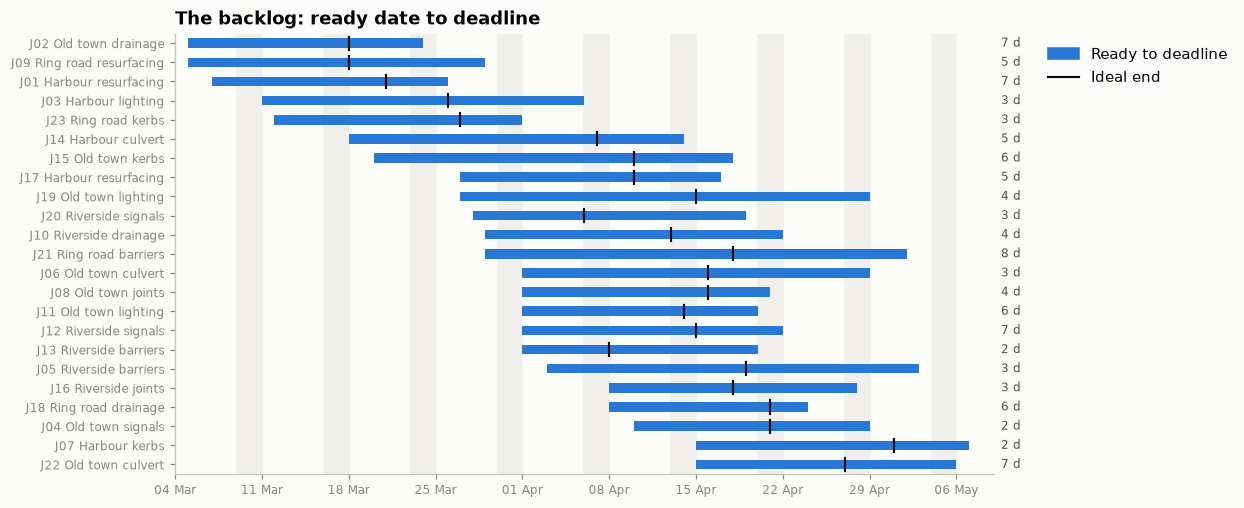

In [3]:
def as_num(day):
    return mdates.date2num(day)


def draw_calendar(ax, last_day):
    """Weekend bands and a tick on every Monday."""
    day = FIRST_DAY
    while day < last_day:
        if day.weekday() == 5:
            ax.axvspan(as_num(day), as_num(day + timedelta(days=2)), color="#f0efec", zorder=0)
        day += timedelta(days=1)
    ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    ax.set_xlim(as_num(FIRST_DAY), as_num(last_day))
    ax.tick_params(axis="x", labelsize=8)


jobs = sorted(problem.jobs, key=lambda j: j.min_start_date)
last_day = max(j.max_end_date for j in jobs) + timedelta(days=2)
fig, ax = plt.subplots(figsize=(9.6, 5.2))
draw_calendar(ax, last_day)
for row, job in enumerate(jobs):
    ax.barh(row, (job.max_end_date - job.min_start_date).days, left=as_num(job.min_start_date), height=0.5,
            color=COLORS[0], zorder=2)
    ax.plot([as_num(job.ideal_end_date)] * 2, [row - 0.34, row + 0.34], color="#0b0b0b", linewidth=1.4,
            zorder=3)
    ax.text(as_num(last_day) + 0.6, row, f"{job.duration_in_days} d", va="center", color=INK, fontsize=8)
ax.set_yticks(range(len(jobs)), [f"{j.id} {j.name}" for j in jobs], fontsize=8)
ax.set_ylim(len(jobs) - 0.5, -0.5)
ax.set_title("The backlog: ready date to deadline")
ax.legend(handles=[Patch(color=COLORS[0], label="Ready to deadline"),
                   Line2D([], [], color="#0b0b0b", linewidth=1.4, label="Ideal end")],
          loc="upper left", bbox_to_anchor=(1.05, 1))
plt.show()

## 2. Solve it

`mnt.solve` works on the engine object and changes it in place, so the path is model to engine and
back: `to_core()`, `solve`, `from_core()`. The result carries each job's `crew_id`, `start_date` and
`end_date`.

The score has two levels, compared in order:

- **hard**: the days of rule breaks, where `0` means the plan can be carried out
    - one point for each day two jobs overlap on the same crew
    - one point for each day a job starts before it is ready
    - one point for each day a job ends after its deadline
- **soft**: the cost of a plan that can be carried out
    - `-1,000,000` for each day a job ends after its ideal end
    - `-1,000` for each shared tag on each day two jobs overlap
    - `-1` for each day a job ends before its ideal end

The soft weights mean one late day outweighs any reasonable number of tag overlaps, and finishing
early is a very small cost. All days are calendar days, so a weekend inside a delay counts.

In [4]:
SEED, TIME_LIMIT = 42, 3.0


def solve_model(schedule, **options):
    """Solve a model and return the solved model."""
    core = schedule.to_core()
    mnt.solve(core, **options)
    return MaintenanceScheduleModel.from_core(core)


plan = solve_model(make_schedule(), time_limit_seconds=TIME_LIMIT, random_seed=SEED)

print("feasible:", plan.score_hard == 0)
print("score   :", plan.score_hard, "/", plan.score_soft)

feasible: True
score   : 0 / -27011070.0


### The crew calendar

Jobs are grouped by crew and sorted by start. Each bar covers only the working days of a job, so a
job that runs over a weekend shows a gap. The light bar behind it is the job's window from ready date
to deadline, and the tick is its ideal end. Late jobs show how many days they miss the ideal end by.

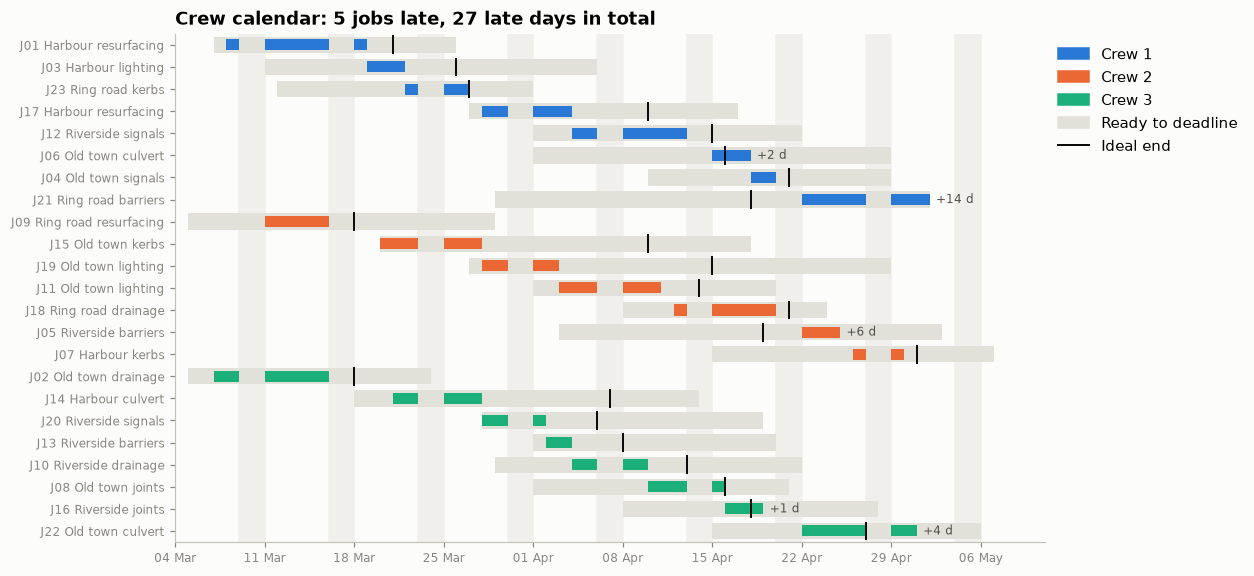

In [5]:
def days_late(job):
    return max(0, (job.end_date - job.ideal_end_date).days)


def working_spans(job):
    """(first day, length) of each Monday-to-Friday run of a job."""
    spans, day = [], job.start_date
    while day < job.end_date:
        if day.weekday() > 4:
            day += timedelta(days=1)
            continue
        run = min(5 - day.weekday(), (job.end_date - day).days)
        spans.append((day, run))
        day += timedelta(days=run)
    return spans


def crew_rows(solution):
    """Rows for the chart: each crew's jobs in start order, crew by crew."""
    return [(k, job) for k, crew in enumerate(solution.crews)
            for job in sorted((j for j in solution.jobs if j.crew_id == crew.id), key=lambda j: j.start_date)]


def draw_plan(ax, solution, outlined=()):
    rows = crew_rows(solution)
    last = max(d for j in solution.jobs for d in (j.max_end_date, j.end_date)) + timedelta(days=4)
    draw_calendar(ax, last)
    for row, (k, job) in enumerate(rows):
        ax.barh(row, (job.max_end_date - job.min_start_date).days, left=as_num(job.min_start_date),
                height=0.74, color="#e1e0d9", zorder=1)
        for day, length in working_spans(job):
            ax.barh(row, length, left=as_num(day), height=0.5, color=COLORS[k], zorder=2,
                    edgecolor="#0b0b0b" if job.id in outlined else "none", linewidth=1.1)
        ax.plot([as_num(job.ideal_end_date)] * 2, [row - 0.38, row + 0.38], color="#0b0b0b", linewidth=1.3,
                zorder=3)
        if days_late(job):
            ax.text(as_num(job.end_date) + 0.5, row, f"+{days_late(job)} d", va="center", color=INK, fontsize=8,
                    zorder=4)
    ax.set_yticks(range(len(rows)), [f"{j.id} {j.name}" for _, j in rows], fontsize=8)
    ax.set_ylim(len(rows) - 0.5, -0.5)
    return [Patch(color=COLORS[k], label=crew.name) for k, crew in enumerate(solution.crews)] + [
        Patch(color="#e1e0d9", label="Ready to deadline"),
        Line2D([], [], color="#0b0b0b", linewidth=1.3, label="Ideal end"),
    ]


late_total = sum(days_late(j) for j in plan.jobs)
fig, ax = plt.subplots(figsize=(10.2, 6))
handles = draw_plan(ax, plan)
jobs_late = sum(days_late(j) > 0 for j in plan.jobs)
ax.set_title(f"Crew calendar: {jobs_late} jobs late, {late_total} late days in total")
ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

## 3. Check the result yourself

The solved model is plain data. This recomputes every rule from dates alone, with no solver code, and
rebuilds the soft score from those counts. A day counts once for each pair of jobs running on it, and
for tags once per shared tag.

In [6]:
def overlap_days(a, b):
    return max(0, (min(a.end_date, b.end_date) - max(a.start_date, b.start_date)).days)


def audit(solution):
    pairs = [(a, b) for i, a in enumerate(solution.jobs) for b in solution.jobs[i + 1:]]
    return {
        "crew overlap days": sum(overlap_days(a, b) for a, b in pairs if a.crew_id == b.crew_id),
        "days before ready": sum(max(0, (j.min_start_date - j.start_date).days) for j in solution.jobs),
        "days past deadline": sum(max(0, (j.end_date - j.max_end_date).days) for j in solution.jobs),
        "late days": sum(days_late(j) for j in solution.jobs),
        "tag overlap days": sum(overlap_days(a, b) * len(set(a.tags) & set(b.tags)) for a, b in pairs),
        "early days": sum(max(0, (j.ideal_end_date - j.end_date).days) for j in solution.jobs),
    }


check = audit(plan)
for rule, value in check.items():
    print(f"{rule:19}: {value}")

rebuilt = -(1_000_000 * check["late days"] + 1_000 * check["tag overlap days"] + check["early days"])
print(f"rebuilt soft score : {rebuilt}, solver says {plan.score_soft:.0f}")
print("every job on a working day:", all(j.start_date.weekday() < 5 for j in plan.jobs))

crew overlap days  : 0
days before ready  : 0
days past deadline : 0
late days          : 27
tag overlap days   : 11
early days         : 70
rebuilt soft score : -27011070, solver says -27011070
every job on a working day: True


## 4. Change the rules, not the solver

Every rule is a plugin. `list_constraints()` shows what ships with this use case, and passing
`constraints=` to `mnt.solve` replaces the set. Only listed rules are scored.

In [7]:
for name in mnt.list_constraints():
    print(name)

min_start_date
max_end_date
before_ideal_end_date
after_ideal_end_date
crew_conflict
tag_conflict


`weight` scales a rule, `hard` moves it between levels, and `exponent=2` makes large violations much
costlier than small ones.

Two changes to the objective, each a different answer to "what does a bad plan look like":

- **No very late job.** `AfterIdealEndDate(exponent=2)` squares each job's delay, so one job ten days
  late now costs more than ten jobs one day late. The default charges them the same.
- **Protect the streets.** `TagConflict(weight=10_000_000)` makes a day of overlap in a district cost
  ten late days, where the default makes it a thousandth of one.

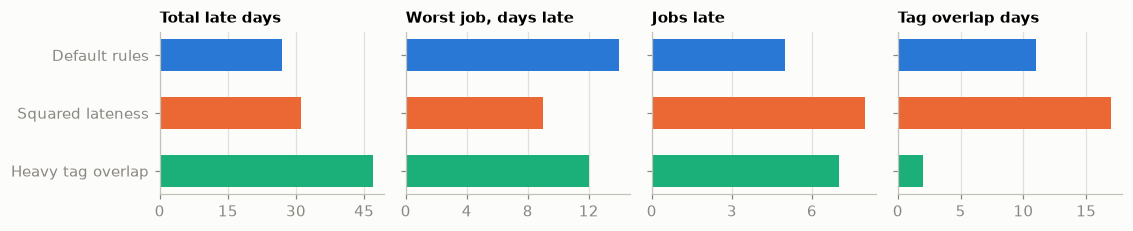

Default rules     : hard 0, total late days 27, worst job, days late 14, jobs late 5, tag overlap days 11
Squared lateness  : hard 0, total late days 31, worst job, days late 9, jobs late 8, tag overlap days 17
Heavy tag overlap : hard 0, total late days 47, worst job, days late 12, jobs late 7, tag overlap days 2


In [8]:
kept = [rules.min_start_date, rules.max_end_date, rules.before_ideal_end_date, rules.crew_conflict]
objectives = {
    "Default rules": None,
    "Squared lateness": [*kept, rules.AfterIdealEndDate(exponent=2), rules.tag_conflict],
    "Heavy tag overlap": [*kept, rules.after_ideal_end_date, rules.TagConflict(weight=10_000_000)],
}
results = {
    name: solve_model(make_schedule(), time_limit_seconds=TIME_LIMIT, random_seed=SEED, constraints=constraints)
    for name, constraints in objectives.items()
}

measures = {
    "Total late days": lambda s: audit(s)["late days"],
    "Worst job, days late": lambda s: max(days_late(j) for j in s.jobs),
    "Jobs late": lambda s: sum(days_late(j) > 0 for j in s.jobs),
    "Tag overlap days": lambda s: audit(s)["tag overlap days"],
}
y = np.arange(len(results))
fig, axes = plt.subplots(1, 4, figsize=(10.4, 2.2), sharey=True)
for ax, (title, measure) in zip(axes, measures.items()):
    ax.barh(y, [measure(s) for s in results.values()], height=0.55, color=COLORS[:len(results)])
    ax.set_title(title, fontsize=10)
    ax.grid(True, axis="x")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=4))
axes[0].set_yticks(y, list(results))
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

for name, solution in results.items():
    print(f"{name:18}: hard {solution.score_hard}, "
          + ", ".join(f"{title.lower()} {measure(solution)}" for title, measure in measures.items()))

The soft scores of these runs cannot be compared with each other, because each run prices a day
differently. Compare the measures in the chart, which are counted from the plans. All three are the
best found in the time limit rather than proven optima, and section 6 shows how much two runs can
differ, so read a small gap as noise.

## 5. What another crew buys

The calendar has room for the work only just. This repeats the solve with fewer and more crews.
When crews run out, the hard level pays first, because a job past its deadline or stacked on a crew
breaks a rule that lateness does not.

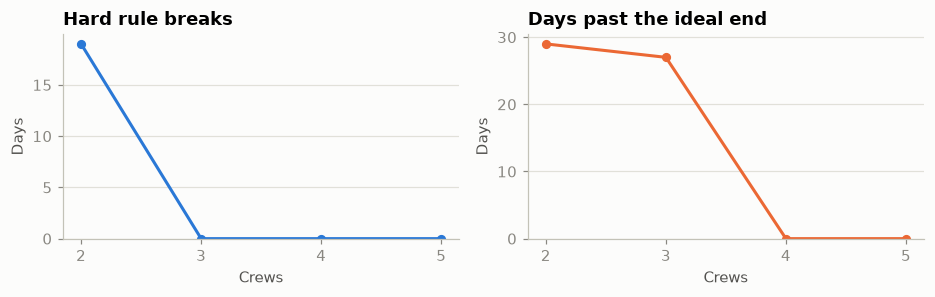

2 crews: hard -19, crew overlap 19, late 29, tag overlap 15
3 crews: hard 0, crew overlap 0, late 27, tag overlap 11
4 crews: hard 0, crew overlap 0, late 0, tag overlap 12
5 crews: hard 0, crew overlap 0, late 0, tag overlap 11


In [9]:
crew_counts = [2, 3, 4, 5]
by_crews = [solve_model(make_schedule(n), time_limit_seconds=1.5, random_seed=SEED) for n in crew_counts]

fig, axes = plt.subplots(1, 2, figsize=(8.6, 2.8), sharex=True)
hard_days = [-s.score_hard for s in by_crews]
late_days = [audit(s)["late days"] for s in by_crews]
axes[0].plot(crew_counts, hard_days, color=COLORS[0], linewidth=2, marker="o", markersize=5)
axes[0].set(title="Hard rule breaks", xlabel="Crews", ylabel="Days")
axes[1].plot(crew_counts, late_days, color=COLORS[1], linewidth=2, marker="o", markersize=5)
axes[1].set(title="Days past the ideal end", xlabel="Crews", ylabel="Days")
for ax in axes:
    ax.set_xticks(crew_counts)
    ax.set_ylim(bottom=0)
    ax.grid(True, axis="y")
plt.tight_layout()
plt.show()

for count, solution in zip(crew_counts, by_crews):
    check = audit(solution)
    print(f"{count} crews: hard {solution.score_hard}, crew overlap {check['crew overlap days']}, "
          f"late {check['late days']}, tag overlap {check['tag overlap days']}")

Read the two charts together. With too few crews, work that does not fit is stacked on a crew and shows
up in the left chart, so the right chart understates the shortage. Where a line sits at zero, one more
crew buys nothing on that measure. The tag rule ignores which crew runs a job, so
extra crews do not remove tag overlap: they make it easier to run two jobs at once, not harder.

## 6. Restart from an existing plan

`with_initial_solution(problem, solution)` returns a copy of `problem` whose search starts from
`solution`. Jobs are matched by id, a job the solution leaves out is placed by the construction
heuristic, and a complete solution is exactly where the search starts.

Runs on this problem can land far apart, and ruin and recreate does much of the work. Both are visible
here.

In [10]:
ROUND_SECONDS = 0.3


def round_solve(start=None, seed=0, **options):
    """One short search, from nothing or from an earlier plan."""
    config = mnt.SolverConfig()
    config.spent_limit_seconds = ROUND_SECONDS
    config.random_seed = seed
    for option, value in options.items():
        setattr(config, option, value)
    schedule = make_schedule() if start is None else mnt.with_initial_solution(make_schedule(), start)
    return solve_model(schedule, config=config)


def late_days_of(solution):
    return audit(solution)["late days"]


without_ruin = round_solve(seed=1, spent_limit_seconds=1.0, ruin_recreate=False)
print("late days, ruin and recreate off, 1 s:", late_days_of(without_ruin))
print("late days, ruin and recreate on, 1 s :", late_days_of(round_solve(seed=1, spent_limit_seconds=1.0)))
print("late days, six seeds, each 0.3 s     :", sorted(late_days_of(round_solve(seed=s)) for s in range(6)))

late days, ruin and recreate off, 1 s: 28
late days, ruin and recreate on, 1 s : 17
late days, six seeds, each 0.3 s     : [17, 17, 18, 19, 22, 24]


**Give each restart its own `random_seed`.** A solve returns the best plan it saw, and the same start
with the same seed repeats the same search, so once a round finds nothing, every later round returns
the same plan. Both lines below begin from the same first answer.

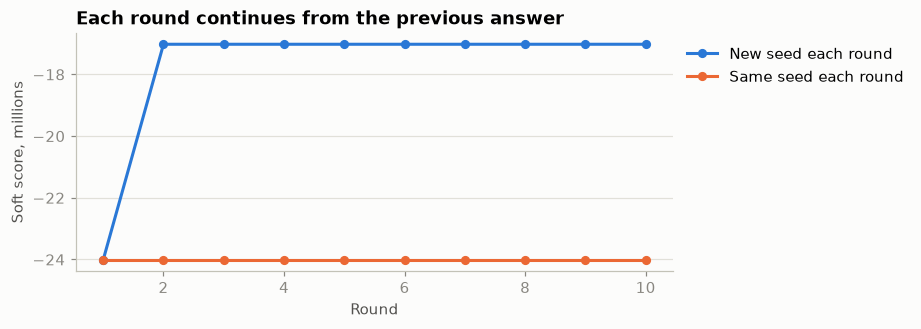

same seed: 9 of 9 restarts returned their starting plan
new seed : 7 of 9 restarts returned their starting plan


In [11]:
ROUNDS, FIRST_SEED = 10, 2


first_answer = round_solve(seed=FIRST_SEED)


def run_rounds(seed_of_round):
    solution = first_answer
    history, repeats = [solution.score_soft], 0
    for round_number in range(1, ROUNDS):
        previous = [(j.crew_id, j.start_date) for j in solution.jobs]
        solution = round_solve(solution, seed=seed_of_round(round_number))
        history.append(solution.score_soft)
        repeats += previous == [(j.crew_id, j.start_date) for j in solution.jobs]
    return history, repeats


same_seed, same_repeats = run_rounds(lambda round_number: FIRST_SEED)
new_seed, new_repeats = run_rounds(lambda round_number: FIRST_SEED + 10 * round_number)

fig, ax = plt.subplots(figsize=(7, 2.8))
turns = range(1, ROUNDS + 1)
ax.plot(turns, [s / 1e6 for s in new_seed], color=COLORS[0], linewidth=2, marker="o", markersize=5,
        label="New seed each round")
ax.plot(turns, [s / 1e6 for s in same_seed], color=COLORS[1], linewidth=2, marker="o", markersize=5,
        label="Same seed each round")
ax.set(title="Each round continues from the previous answer", xlabel="Round", ylabel="Soft score, millions")
ax.grid(True, axis="y")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

print(f"same seed: {same_repeats} of {ROUNDS - 1} restarts returned their starting plan")
print(f"new seed : {new_repeats} of {ROUNDS - 1} restarts returned their starting plan")

A new seed does not guarantee progress either. When the blue line levels off the search has stalled,
which is not a proof that the plan is optimal.

### Fit in an urgent job

Two weeks in, a burst water main needs a crew. Work that has started cannot move, so those jobs are
**pinned**: a pinned job keeps its crew and start date whatever the solution says, counts in the
score, and never moves. Jobs that have not started get today as their new ready date, otherwise the
solver could move them into the past.

Nothing in the score rewards keeping a plan stable, and a crew that has already booked its road
closures has a real cost when dates move. So this compares three replans by the jobs they move as well
as by the score:

- **Open jobs free, old plan**: the search starts from the old plan and may move any open job.
- **Open jobs free, no plan**: the same pins, with the open jobs placed again.
- **Only the urgent job open**: every other job is pinned, so it has to fit around them.

3 of 23 jobs have started
Open jobs free, old plan : hard 0, 30 late days, 1 jobs moved, urgent job C1 from 2030-03-22, pins kept: True
Open jobs free, no plan  : hard 0, 34 late days, 19 jobs moved, urgent job C1 from 2030-03-19, pins kept: True
Only the urgent job open : hard -1, 27 late days, 0 jobs moved, urgent job C3 from 2030-03-18, pins kept: True


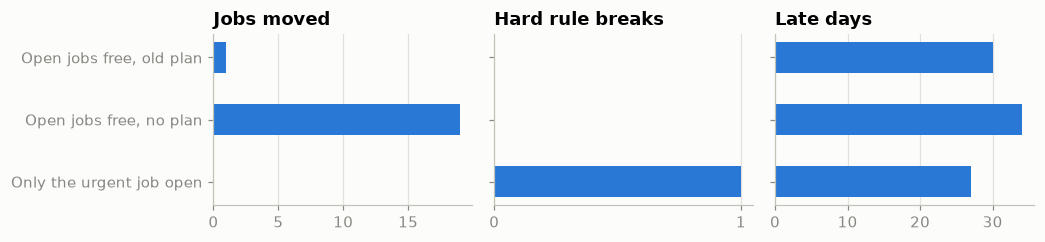

In [12]:
TODAY, REPLAN_SECONDS, REPLAN_SEED = FIRST_DAY + timedelta(weeks=2), 1.0, SEED + 1
old = {j.id: j for j in plan.jobs}


def replanning_problem(keep):
    """The backlog plus the urgent job, with every job where keep(job) is true pinned."""
    schedule = make_schedule()
    for job in schedule.jobs:
        if keep(old[job.id]):
            job.crew_id, job.start_date, job.pinned = old[job.id].crew_id, old[job.id].start_date, True
        else:
            job.min_start_date = max(job.min_start_date, TODAY)
    schedule.jobs.append(JobModel(
        id="J99", name="Harbour water main", duration_in_days=4, min_start_date=TODAY,
        ideal_end_date=TODAY + timedelta(days=7), max_end_date=TODAY + timedelta(days=14), tags=["Harbour"],
    ))
    return schedule


def has_started(job):
    return job.start_date < TODAY


def always(job):
    return True


def placement(job):
    return job.crew_id, job.start_date


def moved_jobs(solution):
    return [j.id for j in solution.jobs if j.id in old and placement(j) != placement(old[j.id])]


replans = {
    "Open jobs free, old plan": mnt.with_initial_solution(replanning_problem(has_started), plan),
    "Open jobs free, no plan": replanning_problem(has_started),
    "Only the urgent job open": mnt.with_initial_solution(replanning_problem(always), plan),
}
replans = {name: solve_model(schedule, time_limit_seconds=REPLAN_SECONDS, random_seed=REPLAN_SEED)
           for name, schedule in replans.items()}

print(f"{sum(has_started(j) for j in plan.jobs)} of {len(plan.jobs)} jobs have started")
for name, solution in replans.items():
    kept_in_place = all(placement(j) == placement(old[j.id]) for j in solution.jobs if j.pinned)
    urgent = next(j for j in solution.jobs if j.id == "J99")
    print(f"{name:25}: hard {solution.score_hard}, {audit(solution)['late days']} late days, "
          f"{len(moved_jobs(solution))} jobs moved, urgent job {urgent.crew_id} from {urgent.start_date}, "
          f"pins kept: {kept_in_place}")

names = list(replans)
y = np.arange(len(names))
panels = [("Jobs moved", [len(moved_jobs(s)) for s in replans.values()]),
          ("Hard rule breaks", [-s.score_hard for s in replans.values()]),
          ("Late days", [audit(s)["late days"] for s in replans.values()])]
fig, axes = plt.subplots(1, 3, figsize=(9.6, 2.3), sharey=True)
for ax, (title, values) in zip(axes, panels):
    ax.barh(y, values, height=0.5, color=COLORS[0])
    ax.set_title(title)
    ax.set_xlim(0, max(*values, 1) * 1.05)
    ax.grid(True, axis="x")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=4))
axes[0].set_yticks(y, names)
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

Below is the first replan, where open jobs may move and the search starts from the old plan. Outlined
bars are the jobs that moved, and the line marks today.

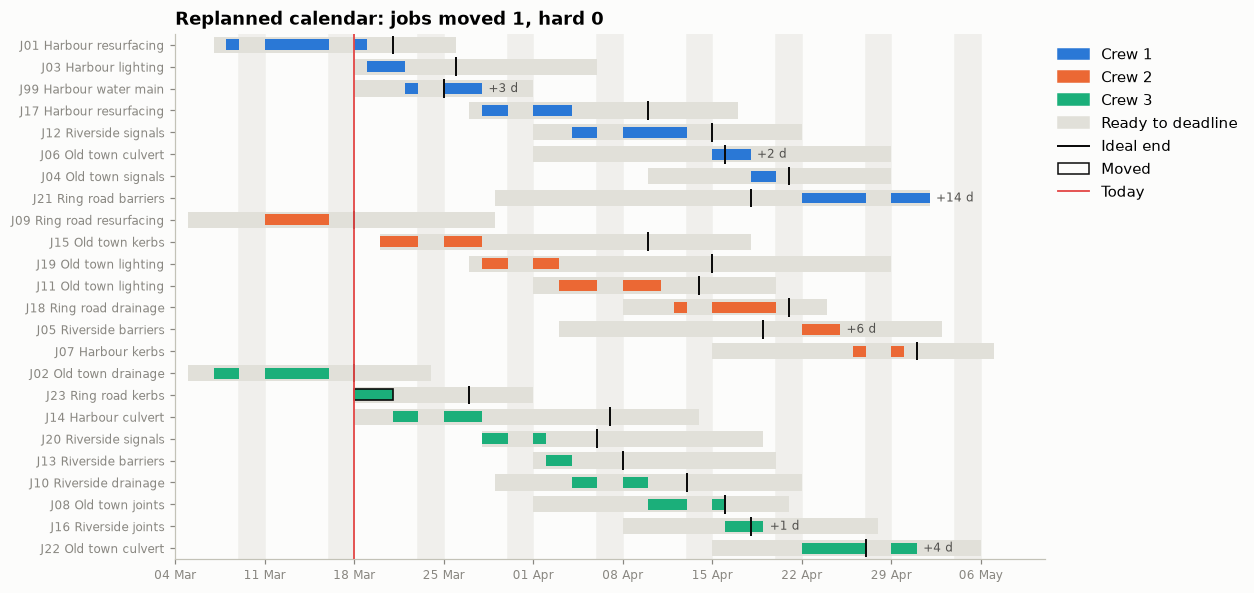

In [13]:
shown = replans["Open jobs free, old plan"]
fig, ax = plt.subplots(figsize=(10.2, 6.2))
handles = draw_plan(ax, shown, outlined=set(moved_jobs(shown)))
ax.axvline(as_num(TODAY), color=COLORS[7], linewidth=1.2, zorder=4)
ax.set_title(f"Replanned calendar: jobs moved {len(moved_jobs(shown))}, hard {shown.score_hard}")
handles += [Patch(facecolor="none", edgecolor="#0b0b0b", label="Moved"),
            Line2D([], [], color=COLORS[7], linewidth=1.2, label="Today")]
ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

## Next steps

- `use-cases/maintenance-scheduling/README.md` covers the basic solver options and how to add your own
  rules in C++.
- For the same idea with hours instead of days and one machine per job, see
  `semiconductor-scheduling.ipynb`.